In [1]:
import pandas as pd
import numpy as np
import torch

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

In [10]:
device = torch.device("cpu")

path = "dataset/gt_2015.csv"
df = pd.read_csv(path)

Y_raw = df['NOX'].values
X_raw = df.iloc[:, :9].values

X = torch.from_numpy(X_raw).float()
y = torch.from_numpy(Y_raw).float().unsqueeze(1) #Duda porque solamente aqui se usa unsqueeze

m = X.shape[0]

torch.manual_seed(42)
indices = torch.randperm(m)
X = X[indices]
y = y[indices]

train_size = int(0.8 * m)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Total de muestras (m): {m}")
print(f"X_train shape: {X_train.shape} | Dispositivo: {X_train.device}")
print(f"X_test shape:  {X_test.shape}  | Dispositivo: {X_test.device}")

print(f"Y_train shape: {y_train.shape} | Dispositivo: {y_train.device}")
print(f"Y_test shape:  {y_test.shape}  | Dispositivo: {y_test.device}")

Total de muestras (m): 7384
X_train shape: torch.Size([5907, 9]) | Dispositivo: cpu
X_test shape:  torch.Size([1477, 9])  | Dispositivo: cpu
Y_train shape: torch.Size([5907, 1]) | Dispositivo: cpu
Y_test shape:  torch.Size([1477, 1])  | Dispositivo: cpu


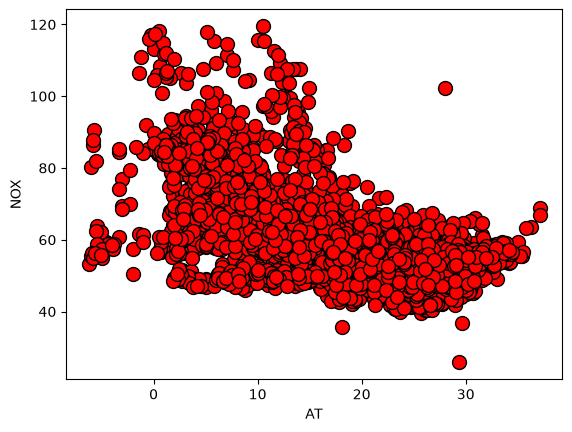

In [11]:
def plotData(x, y):

    fig = pyplot.figure()

    pyplot.plot(x, y, 'ro', ms=10, mec='k')
    pyplot.ylabel('NOX')
    pyplot.xlabel('AT')

plotData(X_train[:, 0], y_train)

In [12]:
print(X_train)

tensor([[1.7558e+01, 1.0146e+03, 8.5274e+01,  ..., 5.5034e+02, 1.1150e+02,
         1.0594e+01],
        [1.3697e+01, 1.0179e+03, 7.5137e+01,  ..., 5.5011e+02, 1.2912e+02,
         1.1600e+01],
        [4.8238e-01, 1.0261e+03, 6.3519e+01,  ..., 5.3540e+02, 1.1592e+02,
         1.0860e+01],
        ...,
        [2.2536e+01, 1.0096e+03, 8.1512e+01,  ..., 5.5017e+02, 1.1045e+02,
         1.0470e+01],
        [1.2636e+01, 1.0267e+03, 6.7414e+01,  ..., 5.4953e+02, 1.0971e+02,
         1.0325e+01],
        [9.3518e+00, 1.0137e+03, 6.3125e+01,  ..., 5.4974e+02, 1.2883e+02,
         1.1619e+01]])


In [13]:
print(y_train)

tensor([[ 55.2540],
        [ 55.8960],
        [118.2700],
        ...,
        [ 52.6920],
        [ 66.5030],
        [ 70.4840]])


In [14]:
def featureNormalize(X,y):
    
    mu = X.mean(dim=0)
    sigma = X.std(dim=0)

    mu_y = y.mean(dim=0)
    sigma_y = y.std(dim=0)

    X_norm = (X - mu) / sigma
    y_norm = (y - mu_y) / sigma_y

    return X_norm, y_norm, mu, mu_y, sigma, sigma_y


X_train_norm, y_train_norm, mu, mu_y, sigma, sigma_y = featureNormalize(X, y)

print(X_train_norm)
print(y_train_norm)

tensor([[ 0.0411,  0.0132,  1.2279,  ...,  0.6736, -1.3903, -1.3224],
        [-0.4358,  0.4917,  0.4792,  ...,  0.6317, -0.3012, -0.4373],
        [-2.0681,  1.6809, -0.3787,  ..., -2.0482, -1.1171, -1.0884],
        ...,
        [-0.3431,  0.0422,  0.7279,  ...,  0.6736, -0.5923, -0.6027],
        [-0.5747,  0.1727,  0.4123,  ...,  0.6135, -0.0521, -0.1346],
        [-0.4697, -1.1905, -0.4544,  ...,  0.5971, -0.1875, -0.4012]])
tensor([[-0.4165],
        [-0.3588],
        [ 5.2441],
        ...,
        [-0.2361],
        [ 0.7064],
        [ 0.8855]])


In [52]:
def generar_caracteristicas_polinomicas(X, grado):

    caracteristicas = []
    
    for p in range(1, grado + 1):
        caracteristicas.append(X ** p)
        
    # Concatenamos a lo largo de las columnas (dim=1)
    return torch.cat(caracteristicas, dim=1)

grado = 1

# Generamos las características polinómicas para Train y Test
X_train_poly = generar_caracteristicas_polinomicas(X_train_norm, grado)

print(f"Forma de X_train original: {X_train_norm.shape}")
print(f"Forma de X_train polinómico (Grado {grado}): {X_train_poly.shape}")

Forma de X_train original: torch.Size([7384, 9])
Forma de X_train polinómico (Grado 1): torch.Size([7384, 9])


In [59]:
D_in, H, D_out = 9, 32, 1

model = torch.nn.Sequential(
    torch.nn.Linear(D_in, H),
    torch.nn.ReLU(),
    torch.nn.Linear(H, D_out)
).to(device)

criterion = torch.nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

epochs = 10000
log_each = 1000
l = []

model.train()

for e in range(1, epochs + 1):

    # 1. Forward pass
    y_pred = model(X_train_poly)

    # 2. Calcular el loss
    loss = criterion(y_pred, y_train_norm)
    l.append(loss.item())

    # 3. Limpiar gradientes
    optimizer.zero_grad()

    # 4. Backward pass
    loss.backward()

    # 5. Actualizar pesos
    optimizer.step()

    # Imprimimos el loss PUNTUAL de la época actual (no el promedio de la lista)
    if not e % log_each:
        print(f"Epoch {e}/{epochs} | Loss actual: {loss.item():.5f}")

Epoch 1000/10000 | Loss actual: 0.11843
Epoch 2000/10000 | Loss actual: 0.10711
Epoch 3000/10000 | Loss actual: 0.10665
Epoch 4000/10000 | Loss actual: 0.10514
Epoch 5000/10000 | Loss actual: 0.10457
Epoch 6000/10000 | Loss actual: 0.10274
Epoch 7000/10000 | Loss actual: 0.10030
Epoch 8000/10000 | Loss actual: 0.09870
Epoch 9000/10000 | Loss actual: 0.10029
Epoch 10000/10000 | Loss actual: 0.09681


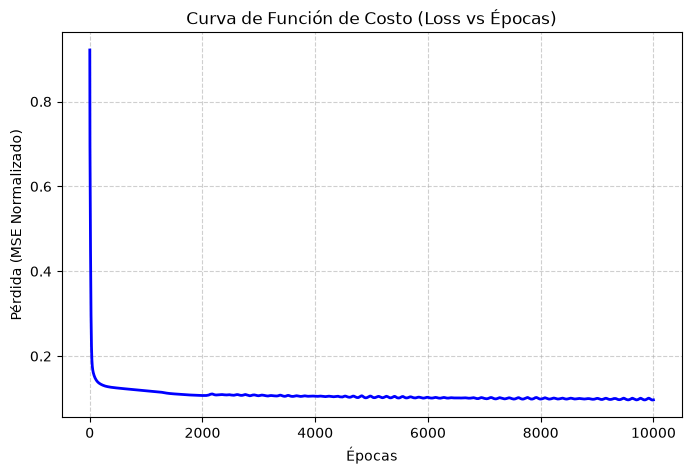

In [60]:
pyplot.figure(figsize=(8, 5))

pyplot.plot(range(1, epochs + 1), l, color='blue', linewidth=2)

pyplot.title('Curva de Función de Costo (Loss vs Épocas)')
pyplot.xlabel('Épocas')
pyplot.ylabel('Pérdida (MSE Normalizado)')
pyplot.grid(True, linestyle='--', alpha=0.6)

pyplot.show()

In [61]:
model.eval()

X_test_norm = (X_test - mu) / sigma
y_test_norm = (y_test - mu_y) / sigma_y

X_test_poly = generar_caracteristicas_polinomicas(X_test_norm, grado)

with torch.no_grad():

    y_pred_test = model(X_test_poly)
    
    y_true_mean = torch.mean(y_test_norm)
    
    ss_res = torch.sum((y_test_norm - y_pred_test) ** 2)
    
    ss_tot = torch.sum((y_test_norm - y_true_mean) ** 2)
    
    r2_score = 1 - (ss_res / ss_tot)
    
    porcentaje_acierto = r2_score.item() * 100

print(f"\nPorcentaje de aprendizaje/ajuste: {porcentaje_acierto:.2f}%")


Porcentaje de aprendizaje/ajuste: 90.79%
